In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Se quiere preparar el plan de cadena crítica de un proyecto. Para cada actividad, su responsable ha dado una estimación **segura** (con la que cumpliría aproximadamente nueve de cada diez veces, el percentil 90) y una estimación **agresiva pero alcanzable** (la mediana, el percentil 50), ambas en días. Algunas actividades las ejecuta el mismo equipo (columna *recurso*); cada equipo sólo puede atender una actividad a la vez y no la interrumpe. Los conflictos de recursos se resuelven programando día a día: cuando varias actividades del mismo equipo pueden empezar, tiene prioridad la de menor inicio más tardío en el cronograma sin recursos (calculado con las estimaciones agresivas); a igualdad, la de menor duración y, después, la primera por orden alfabético. Todos los colchones se dimensionan por el método de la raíz de la suma de cuadrados y se redondean al día superior; si un colchón de alimentación no cabe en la holgura disponible, se reduce a ella (la cadena crítica no se retrasa).

In [4]:
pregunta_1 = "1. Resuelva los conflictos de recursos con la regla de prioridad, obtenga la red nivelada (prelaciones más enlaces de recurso) y la cadena crítica con las estimaciones agresivas.  "
pregunta_2 = "2. Dimensione el colchón del proyecto y los colchones de alimentación.  "
pregunta_3 = "3. Programe el proyecto (la cadena lo antes posible y las actividades de alimentación lo más tarde posible, con su colchón delante) y dibuje el diagrama de Gantt con los colchones. ¿Qué fecha se compromete con el cliente?  "
pregunta_4 = "4. Compare con el cronograma tradicional: estimaciones seguras con la misma secuencia de los equipos. ¿Cuántos días se ganan con el plan de cadena crítica?  "
pregunta_5 = "5. ¿Antes de qué actividades de la cadena hay que avisar a un equipo (colchones de recursos)? ¿Por qué el aviso no ocupa tiempo en el cronograma?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Resuelva los conflictos de recursos con la regla de prioridad, obtenga la red nivelada (prelaciones más enlaces de recurso) y la cadena crítica con las estimaciones agresivas.  

2. Dimensione el colchón del proyecto y los colchones de alimentación.  

3. Programe el proyecto (la cadena lo antes posible y las actividades de alimentación lo más tarde posible, con su colchón delante) y dibuje el diagrama de Gantt con los colchones. ¿Qué fecha se compromete con el cliente?  

4. Compare con el cronograma tradicional: estimaciones seguras con la misma secuencia de los equipos. ¿Cuántos días se ganan con el plan de cadena crítica?  

5. ¿Antes de qué actividades de la cadena hay que avisar a un equipo (colchones de recursos)? ¿Por qué el aviso no ocupa tiempo en el cronograma?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado (días)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, agresiva, segura, recurso
    ('A'     , '---'      , 3       , 5     , '---'  ),
    ('B'     , '---'      , 4       , 6     , 'X'    ),
    ('C'     , '---'      , 9       , 12    , 'X'    ),
    ('D'     , 'B,C'      , 8       , 12    , '---'  ),
    ('E'     , 'B,C'      , 2       , 3     , '---'  ),
    ('F'     , 'D,E'      , 4       , 5     , '---'  ),
    ('G'     , 'F'        , 3       , 5     , 'X'    ),
    ('H'     , 'A,G'      , 3       , 5     , '---'  ),
], columns=['activity', 'predecessor', 'agresiva', 'segura', 'recurso']).set_index('activity')
datos_enunciado

,predecessor,agresiva,segura,recurso
activity,,,,
A,---,3,5,---
B,---,4,6,X
C,---,9,12,X
D,"B,C",8,12,---
E,"B,C",2,3,---
F,"D,E",4,5,---
G,F,3,5,X
H,"A,G",3,5,---


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
METODO = 'raiz'
equipos = sorted(set(datos_proyecto['recurso']) - {'---'})
datos_proyecto['equipo'] = datos_proyecto['recurso'].replace('---', '')
datos_proyecto['duration'] = datos_proyecto['agresiva']

In [7]:
# Funciones auxiliares de la cadena crítica: cálculos intermedios con los números sustituidos
from math import ceil, sqrt
from pmule import grafico_fiebre_tikz
pd.set_option('display.max_colwidth', None)
GANTT_CC = dict(GANTT_PARAMS, period_width=0.6, activity_inner_text_style=r'\bfseries\small')


def sin_decimales(tabla):
    """Números enteros sin «.0» al mostrar una tabla."""
    return tabla.map(lambda v: f'{v:g}' if isinstance(v, float) else v)


def tabla_margenes(datos, actividades):
    """Margen retirado (segura − agresiva) de cada actividad."""
    t = datos.loc[list(actividades), ['segura', 'agresiva']].copy()
    t['margen = segura − agresiva'] = [f'{s} − {a} = {s - a}' for s, a in zip(t['segura'], t['agresiva'])]
    return t.T


def detalle_colchon(margenes, nombre='colchón'):
    """Colchón por cortar y pegar y por la raíz de la suma de cuadrados (redondeo al día superior)."""
    ms = [int(m) for m in margenes]
    suma, cuad = sum(ms), sum(m * m for m in ms)
    cp, rz = 0.5 * suma, sqrt(cuad)
    return pd.DataFrame({nombre: {
        'cortar y pegar = 0,5·Σ márgenes': f"0,5·({' + '.join(map(str, ms))}) = 0,5·{suma} = {cp:g} → {ceil(cp - 1e-9)}",
        'raíz = √(Σ márgenes²)': f"√({' + '.join(f'{m}²' for m in ms)}) = √{cuad} = {rz:.2f} → {ceil(rz - 1e-9)}"}})


def tabla_alimentacion(plan):
    """Colchones de alimentación: arco en el que desemboca la cadena de alimentación, colchón
    requerido, holgura disponible y colchón adoptado."""
    filas = {}
    for nombre, fila in plan.alimentacion.iterrows():
        ms = [int(x) for x in str(fila['margenes']).split(' + ')]
        if plan.metodo_alimentacion == 'cortar_pegar':
            calc = f"0,5·({' + '.join(map(str, ms))}) = {0.5 * sum(ms):g} → {int(fila['requerido'])}"
        else:
            calc = f"√({' + '.join(f'{m}²' for m in ms)}) = {sqrt(sum(m * m for m in ms)):.2f} → {int(fila['requerido'])}"
        entrada = int(plan.inicio_temprano[fila['antes_de']]) if fila['antes_de'] != 'fin' else int(plan.duracion_cadena)
        fin_p = int(plan.inicio_temprano[fila['desde']] + plan.agresiva[fila['desde']])
        filas[nombre] = {'arco': f"{fila['desde']} → {fila['antes_de']}",
                         'cadena de alimentación': fila['cadena_alimentacion'],
                         'colchón requerido': calc,
                         'holgura disponible = inicio de la cadena − fin más temprano': f"{entrada} − {fin_p} = {int(fila['disponible'])}",
                         'colchón adoptado = mín(requerido, disponible)': int(fila['adoptado'])}
    return pd.DataFrame(filas).T


def detalle_alap(plan):
    """Programación lo más tarde posible de las actividades de alimentación (de la última a la primera)."""
    cadena = set(plan.cadena)
    ca = {(fila['desde'], fila['antes_de']): (n, int(fila['adoptado'])) for n, fila in plan.alimentacion.iterrows()}
    suc = {a: sorted(b for b in plan.predecesoras if a in plan.predecesoras[b]) for a in plan.predecesoras}
    filas = {}
    for a in reversed(plan.orden):
        if a in cadena:
            continue
        cands = []
        for b in suc[a]:
            if b in cadena:
                n, fb = ca[(a, b)]
                cands.append(f'{b} − {n}: {int(plan.inicios[b])} − {fb} = {int(plan.inicios[b]) - fb}')
            else:
                cands.append(f'{b}: {int(plan.inicios[b])}')
        if not suc[a]:
            n, fb = ca[(a, 'fin')]
            cands.append(f'fin − {n}: {plan.duracion_cadena} − {fb} = {plan.duracion_cadena - fb}')
        fin = int(plan.inicios[a] + plan.agresiva[a])
        filas[a] = {'fin = mín(inicio de las sucesoras)': f"mín({'; '.join(cands)}) = {fin}",
                    'inicio = fin − duración': f'{fin} − {int(plan.agresiva[a])} = {int(plan.inicios[a])}',
                    'inicio más temprano': int(plan.inicio_temprano[a])}
    return pd.DataFrame(filas).T


def resumen_informes(plan, informes):
    """Cálculos de cada informe de avance con los números sustituidos."""
    T, CP = plan.duracion_cadena, plan.colchon_proyecto
    columnas = {}
    for inf in informes:
        det = inf['detalle']
        curso = det[det['estado'] == 'en curso']
        pend = det[det['estado'] == 'pendiente']
        partes = [f"{r:g} ({a})" for a, r in curso['restante'].items()] + [f"{int(d)} ({a})" for a, d in pend['agresiva'].items()]
        restante = float(det['restante'].sum())
        pa, pc = inf['pct_avance'], inf['pct_consumo']
        columnas[f"día {inf['dia']}"] = {
            'fin previsto = día + restante de la cadena': f"{inf['dia']} + {' + '.join(partes) if partes else '0'} = {inf['fin_previsto']:g}",
            'colchón consumido': f"{inf['fin_previsto']:g} − {T} = {inf['consumo']:g} días → {inf['consumo']:g}/{CP} = {pc:.1f} %",
            'cadena completada': f"({T} − {restante:g})/{T} = {pa:.1f} %",
            'BPI = % colchón restante / % cadena restante': (f"(100 − {pc:.1f})/(100 − {pa:.1f}) = {inf['bpi']:.2f}" if pa < 100 else '—'),
            'límite verde = 10 + 0,6·avance': f"10 + 0,6·{pa:.1f} = {inf['limite_verde']:.1f} %",
            'límite rojo = 30 + 0,6·avance': f"30 + 0,6·{pa:.1f} = {inf['limite_roja']:.1f} %",
            'zona': inf['zona']}
    return pd.DataFrame(columnas)


def solapes(calendario, datos):
    """Pares de actividades del mismo equipo que se solapan en el cronograma sin recursos."""
    filas = []
    for equipo, grupo in datos[datos['recurso'] != '---'].groupby('recurso'):
        acts = sorted(grupo.index)
        for i, a in enumerate(acts):
            for b in acts[i + 1:]:
                ia = (int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano']))
                ib = (int(calendario.loc[b, 'inicio_mas_temprano']), int(calendario.loc[b, 'fin_mas_temprano']))
                solape = min(ia[1], ib[1]) - max(ia[0], ib[0])
                if solape > 0:
                    filas.append({'equipo': equipo, 'actividades': f'{a} y {b}',
                                  'intervalos': f'{a} [{ia[0]}, {ia[1]}) y {b} [{ib[0]}, {ib[1]})', 'días de solape': solape})
    return pd.DataFrame(filas, columns=['equipo', 'actividades', 'intervalos', 'días de solape']).rename(index=lambda i: i + 1)


def esperas_por_recurso(asignacion):
    """Actividades que esperan a un equipo: desde cuándo están listas, cuándo empiezan y quién las bloquea."""
    t = asignacion.traza
    esp = t[t['decision'] == 'espera']
    filas = {}
    for a, g in esp.groupby('actividad'):
        filas[a] = {'lista desde el día': int(g['periodo'].min()) - 1, 'empieza el día': int(asignacion.inicios[a]),
                    'espera (días)': int(asignacion.inicios[a]) - int(g['periodo'].min()) + 1,
                    'equipo que la bloquea': ', '.join(sorted(set(g['bloqueada_por'])))}
    return pd.DataFrame(filas).T

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Resuelva los conflictos de recursos con la regla de prioridad, obtenga la red nivelada (prelaciones más enlaces de recurso) y la cadena crítica con las estimaciones agresivas.  

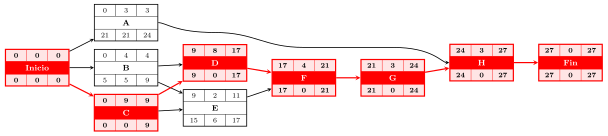

In [9]:
#| fig-cap: "Grafo Roy con las estimaciones agresivas, sin tener en cuenta los equipos"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [10]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [11]:
#| tbl-cap: "Calendario sin tener en cuenta los equipos (estimaciones agresivas)"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
proyecto.display_calendario(datos_proyecto['duration'], grafo="roy")

Actividad,Duración,Inicio más temprano,Fin más temprano,Inicio más tardío,Fin más tardío,H total,H libre,H independiente
A,3,0,3,21,24,21,21,21
B,4,0,4,5,9,5,5,5
C,9,0,9,0,9,0,0,0
D,8,9,17,9,17,0,0,0
E,2,9,11,15,17,6,6,6
F,4,17,21,17,21,0,0,0
G,3,21,24,21,24,0,0,0
H,3,24,27,24,27,0,0,0


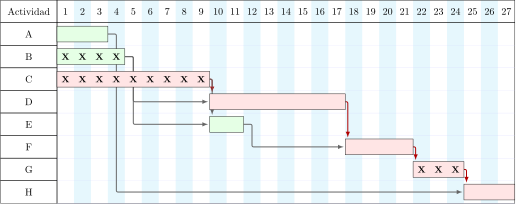

In [12]:
#| fig-cap: "Gantt de inicios más tempranos sin tener en cuenta los equipos (en cada barra, el equipo)"
#| label: fig-ganttLibre
_, dibujo = proyecto.gantt(datos_proyecto, 'duration', 'equipo', tikz=True, params=GANTT_CC)
pinta_tikz(dibujo)

In [13]:
#| tbl-cap: "Actividades de un mismo equipo que se solapan"
#| label: tbl-solapes
solapes(calendario, datos_proyecto)

,equipo,actividades,intervalos,días de solape
1,X,B y C,"B [0, 4) y C [0, 9)",4


In [14]:
T_libre = int(calendario['fin_mas_temprano'].max())
ruta_libre = [a for a in calendario.index if calendario.loc[a, 'H_total'] == 0]
Markdown(f'Sin tener en cuenta los equipos el proyecto dura {T_libre} días y su ruta crítica es {" - ".join(sorted(ruta_libre, key=lambda a: calendario.loc[a, "inicio_mas_temprano"]))}; '
         'pero el cronograma no es realizable: un equipo no puede hacer dos actividades a la vez.')

Sin tener en cuenta los equipos el proyecto dura 27 días y su ruta crítica es C - D - F - G - H; pero el cronograma no es realizable: un equipo no puede hacer dos actividades a la vez.

Se programa día a día con un equipo de cada tipo (límite 1). La prioridad usa el inicio más tardío del calendario anterior. La tabla recoge las actividades que tienen que esperar a su equipo.

In [15]:
demanda = pd.DataFrame({e: (datos_proyecto['recurso'] == e).astype(int) for e in equipos})
demanda['duration'] = datos_proyecto['agresiva']
asignacion = proyecto.asignar_multi(demanda, 'duration', equipos, [1] * len(equipos), dibujar=False)
Markdown(f'Duración con los equipos: **{asignacion.duracion} días** (sin ellos, {T_libre}).')

Duración con los equipos: **31 días** (sin ellos, 27).

In [16]:
#| tbl-cap: "Esperas por falta de equipo"
#| label: tbl-esperas
esperas_por_recurso(asignacion)

,lista desde el día,empieza el día,espera (días),equipo que la bloquea
B,0,9,9,X


In [17]:
plan = proyecto.plan_cadena_critica(datos_proyecto, agresiva='agresiva', segura='segura', recurso='recurso', metodo=METODO)
pd.DataFrame({'orden en que atiende a sus actividades': {e: ' → '.join(plan.secuencias[e]) for e in equipos}})

,orden en que atiende a sus actividades
X,C → B → G


In [18]:
#| tbl-cap: "Enlaces de recurso que se añaden a la red"
#| label: tbl-enlaces
plan.enlaces_recurso.rename(index=lambda i: i + 1)

,de,a,recurso
1,C,B,X


Cada enlace de recurso obliga a que una actividad empiece después de que termine la anterior del mismo equipo. Con ellos la red queda *nivelada*: cualquier programación que respete sus prelaciones respeta los equipos. (Los enlaces que ya están implícitos en las prelaciones no se añaden.)

In [19]:
red = plan.red_nivelada()
proyecto_nivelado = PredecessorTable.from_dataframe_of_strings(red, activity='activity', predecessor='predecessor').create_project()
red[['predecessor']].T

activity,A,B,C,D,E,F,G,H
predecessor,---,C,---,"B,C","B,C","D,E",F,"A,G"


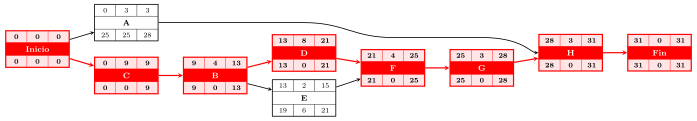

In [20]:
#| fig-cap: "Red nivelada (prelaciones y enlaces de recurso) con las estimaciones agresivas: su camino crítico es la cadena crítica"
#| label: fig-pertNivelado
proyecto_nivelado.roy(durations=red['agresiva'], ranksep=1.2, nodesep=1.2)

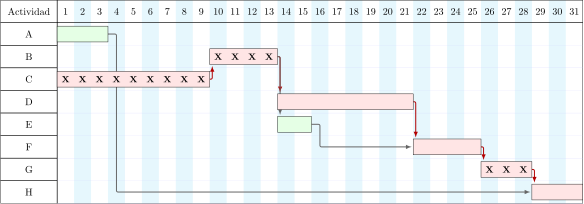

In [21]:
#| fig-cap: "Gantt de la red nivelada (inicios más tempranos)"
#| label: fig-ganttNivelado
_, dibujo = proyecto_nivelado.gantt(datos_proyecto.loc[red.index], 'duration', 'equipo', tikz=True, params=GANTT_CC)
pinta_tikz(dibujo)

In [22]:
#| tbl-cap: "Enlaces de la cadena crítica"
#| label: tbl-cadena
plan.enlaces_cadena.rename(index=lambda i: i + 1)

,de,a,motivo,recurso
1,C,B,recurso,X
2,B,D,precedencia,
3,D,F,precedencia,
4,F,G,precedencia,
5,G,H,precedencia,


In [23]:
Markdown(f'Cadena crítica: **{" - ".join(plan.cadena)}**, {plan.duracion_cadena} días.')

Cadena crítica: **C - B - D - F - G - H**, 31 días.

## Apartado 2

In [24]:
display(Markdown(pregunta_2))

2. Dimensione el colchón del proyecto y los colchones de alimentación.  

In [25]:
#| tbl-cap: "Colchón del proyecto"
#| label: tbl-colchon
detalle_colchon(plan.margen[plan.cadena], 'colchón del proyecto').loc[['raíz = √(Σ márgenes²)']]

,colchón del proyecto
raíz = √(Σ márgenes²),√(3² + 2² + 4² + 1² + 2² + 2²) = √38 = 6.16 → 7


In [26]:
#| tbl-cap: "Colchones de alimentación"
#| label: tbl-alimentacion
tabla_alimentacion(plan)

,arco,cadena de alimentación,colchón requerido,holgura disponible = inicio de la cadena − fin más temprano,"colchón adoptado = mín(requerido, disponible)"
CA1,E → F,E,√(1²) = 1.00 → 1,21 − 15 = 6,1
CA2,A → H,A,√(2²) = 2.00 → 2,28 − 3 = 25,2


In [27]:
Markdown(f'Colchón del proyecto: **{plan.colchon_proyecto} días**. Colchones de alimentación: '
         + '; '.join(f'{n} = {int(f.adoptado)} día(s) antes de {f.antes_de}' for n, f in plan.alimentacion.iterrows()) + '.')

Colchón del proyecto: **7 días**. Colchones de alimentación: CA1 = 1 día(s) antes de F; CA2 = 2 día(s) antes de H.

## Apartado 3

In [28]:
display(Markdown(pregunta_3))

3. Programe el proyecto (la cadena lo antes posible y las actividades de alimentación lo más tarde posible, con su colchón delante) y dibuje el diagrama de Gantt con los colchones. ¿Qué fecha se compromete con el cliente?  

In [29]:
#| tbl-cap: "Programación lo más tarde posible de las actividades de alimentación"
#| label: tbl-alap
detalle_alap(plan)

,fin = mín(inicio de las sucesoras),inicio = fin − duración,inicio más temprano
E,mín(F − CA1: 21 − 1 = 20) = 20,20 − 2 = 18,13
A,mín(H − CA2: 28 − 2 = 26) = 26,26 − 3 = 23,0


In [30]:
#| tbl-cap: "Plan de cadena crítica"
#| label: tbl-plan
plan.tabla().T

,A,B,C,D,E,F,G,H
agresiva,3,4,9,8,2,4,3,3
segura,5,6,12,12,3,5,5,5
margen,2,2,3,4,1,1,2,2
recurso,,X,X,,,,X,
cadena,,sí,sí,sí,,sí,sí,sí
inicio,23,9,0,13,18,21,25,28
fin,26,13,9,21,20,25,28,31


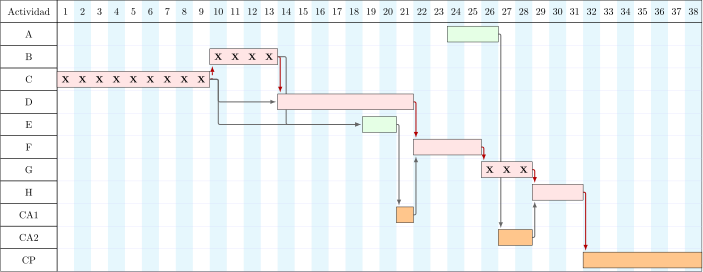

In [31]:
#| fig-cap: "Gantt del plan de cadena crítica: cadena en rojo, alimentación en verde, colchones en naranja; enlaces de recurso discontinuos"
#| label: fig-ganttCCPM
pinta_tikz(plan.gantt_tikz(params=GANTT_CC))

In [32]:
Markdown(f'Fecha comprometida: {plan.duracion_cadena} + {plan.colchon_proyecto} = **{plan.compromiso} días**.')

Fecha comprometida: 31 + 7 = **38 días**.

## Apartado 4

In [33]:
display(Markdown(pregunta_4))

4. Compare con el cronograma tradicional: estimaciones seguras con la misma secuencia de los equipos. ¿Cuántos días se ganan con el plan de cadena crítica?  

In [34]:
datos_proyecto['duration'] = datos_proyecto['segura']
calendario_tradicional = proyecto_nivelado.calendar(datos_proyecto.loc[red.index, 'segura'])
ruta_tradicional = [a for a in calendario_tradicional.sort_values('inicio_mas_temprano').index if calendario_tradicional.loc[a, 'H_total'] == 0]
Markdown(f'Con las estimaciones seguras en la red nivelada el proyecto dura **{plan.duracion_tradicional} días** '
         f'(ruta crítica {" - ".join(ruta_tradicional)}). El plan de cadena crítica compromete {plan.compromiso}: '
         f'**{plan.duracion_tradicional - plan.compromiso} días menos**. El margen que el cronograma tradicional reparte entre las '
         f'actividades ({int(plan.margen.sum())} días en total) se sustituye por {plan.colchon_proyecto} días de colchón del proyecto '
         f'y {int(plan.alimentacion["adoptado"].sum())} de colchones de alimentación, situados donde protegen la entrega.')

Con las estimaciones seguras en la red nivelada el proyecto dura **45 días** (ruta crítica C - B - D - F - G - H). El plan de cadena crítica compromete 38: **7 días menos**. El margen que el cronograma tradicional reparte entre las actividades (17 días en total) se sustituye por 7 días de colchón del proyecto y 3 de colchones de alimentación, situados donde protegen la entrega.

## Apartado 5

In [35]:
display(Markdown(pregunta_5))

5. ¿Antes de qué actividades de la cadena hay que avisar a un equipo (colchones de recursos)? ¿Por qué el aviso no ocupa tiempo en el cronograma?  

In [36]:
#| tbl-cap: "Colchones de recursos (avisos)"
#| label: tbl-avisos
plan.colchones_recursos.rename(columns={'antes_de': 'antes de', 'recursos': 'equipo al que se avisa', 'despues_de': 'mientras termina', 'inicio_previsto': 'inicio previsto'}).rename(index=lambda i: i + 1)

,antes de,equipo al que se avisa,mientras termina,inicio previsto
1,G,X,F,25


El colchón de recursos es un aviso, no una espera: el equipo se compromete a estar libre cuando termine la actividad anterior de la cadena (que, por la regla del corredor de relevos, puede terminar antes de lo previsto). Añadir tiempo alargaría la cadena sin protegerla; lo que se protege es la disponibilidad del recurso, que es lo que haría perder días a la cadena.